# Customer Churn Prediction

## 1. Project Overview

Customer churn refers to a situation where customers stop using a company's products or services. Predicting customer churn helps businesses identify customers who are likely to leave and take steps to improve customer retention.

In this project, we will analyze customer data and build machine learning models to predict whether a customer is likely to churn.

## 2. Project Objectives

- Understand and explore the customer dataset.
- Identify patterns and factors associated with customer churn.
- Perform data cleaning and preprocessing.
- Train and compare different machine learning classification models.
- Evaluate model performance using appropriate metrics.
- Derive business insights from the analysis.

## 3. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 4. Machine Learning Approach

This is a **supervised machine learning classification problem** because the dataset contains a target column, `Churn`, that indicates whether a customer has left the service.

In [146]:
import sys
print(sys.executable)

c:\Users\krish\AppData\Local\Programs\Python\Python313\python.exe


In [147]:
import pandas as pd
print(pd.__version__)

3.0.6


In [148]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [149]:
df.shape

(7043, 21)

## 5. Dataset Exploration

In this section, we will explore the dataset's dimensions, column names, data types, and missing values to understand the data before preprocessing.

In [150]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [151]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 6. Initial Dataset Observations

- The dataset contains 7,043 customer records and 21 columns.
- The target variable is `Churn`.
- The dataset contains numerical features such as `tenure`, `MonthlyCharges`, and `SeniorCitizen`.
- It also contains categorical features such as `Contract`, `InternetService`, and `PaymentMethod`.
- The initial missing-value check reports no null values.
- The `TotalCharges` column is stored as a string, so we need to investigate whether it contains blank or invalid values before modeling.

In [152]:
print(df["TotalCharges"].dtype)
blank_charges = df["TotalCharges"].str.strip().eq("").sum()
print("Blank Total_Charges Value:",blank_charges)

str
Blank Total_Charges Value: 11


In [153]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

### Churn Distribution Analysis

The dataset contains approximately 73.46% customers who stayed and 26.54% customers who churned.

This indicates that customer churn is a significant business concern. Since the two classes are not equally represented, model evaluation should include metrics such as precision, recall, and F1-score in addition to accuracy.

In [154]:
df[df["TotalCharges"].str.strip()== ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [155]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(),errors="coerce")
df["TotalCharges"].isnull().sum()

np.int64(11)

In [156]:
df["TotalCharges"].dtype

dtype('float64')

## 7. Exploratory Data Analysis (EDA)

### 7.1 Customer Tenure and Churn

In this analysis, we will compare customer tenure across churn groups to investigate whether customers who have stayed for shorter periods are more likely to churn.

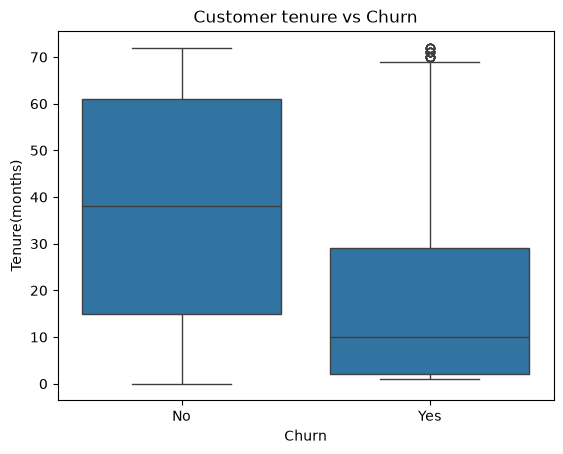

In [157]:
import matplotlib.pyplot as plt 
import seaborn as sns
sns.boxplot(data=df,x="Churn",y="tenure")
plt.title("Customer tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure(months)")
plt.show()

**Observation:** Customers who churned generally had lower tenure than customers who stayed. This suggests that newer customers may be at a higher risk of churn. Further analysis is needed to investigate other factors associated with churn.

In [158]:
churn_by_contract = pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100
churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


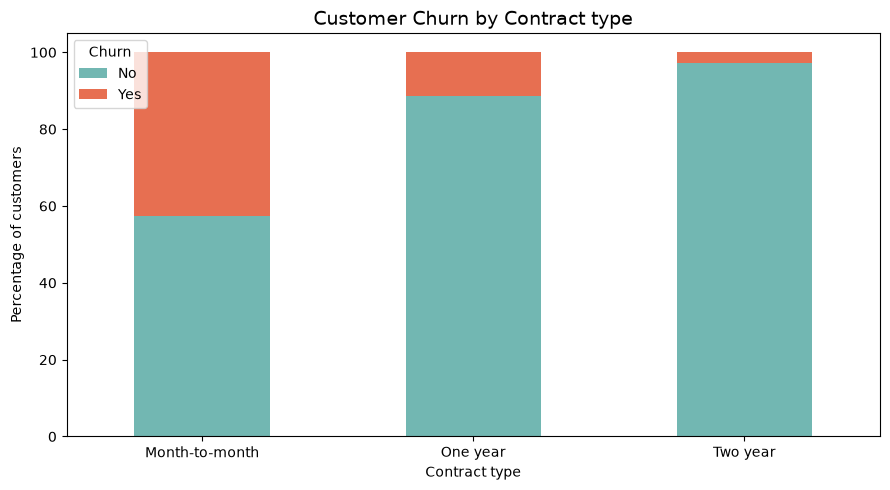

In [159]:
churn_by_contract.plot(kind='bar',stacked=True,figsize=(9,5),color = ("#72B7B2", "#E76F51"))
plt.title("Customer Churn by Contract type",fontsize=14)
plt.xlabel("Contract type")
plt.ylabel("Percentage of customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


**Observation:** Customers with month-to-month contracts have the highest churn rate (42.71%), followed by customers with one-year contracts (11.27%). Customers with two-year contracts have the lowest churn rate (2.83%).

**Business Insight:** The company should investigate why month-to-month customers leave more frequently and consider testing retention strategies, such as improved customer support or suitable long-term contract offers.

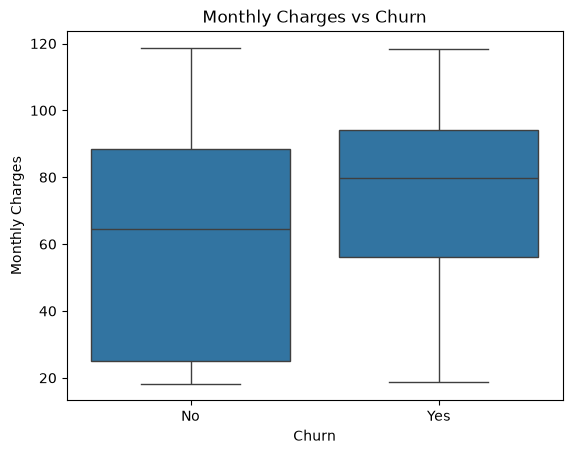

In [160]:
sns.boxplot(data=df,x="Churn",y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

**Observation:** Customers who churned had a higher median monthly charge (approximately 80) than customers who stayed (approximately 65). The monthly charges of customers who stayed also showed a wider spread within the middle 50% of the data.

**Business Insight:** Higher monthly charges may be associated with customer churn. The company could investigate whether pricing or perceived value for money influences customers' decisions to leave.

In [161]:
churn_by_payment = pd.crosstab(df["PaymentMethod"],df["Churn"],normalize="index")*100
churn_by_payment

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


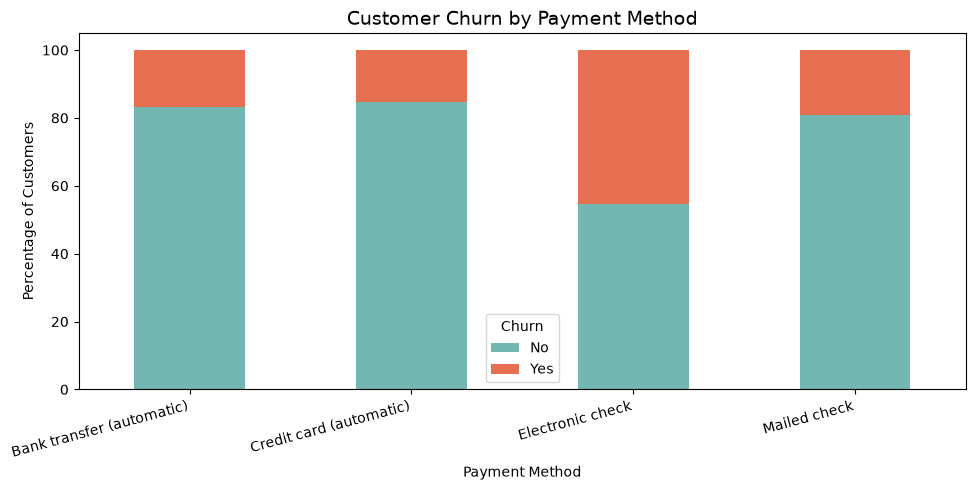

In [162]:
churn_by_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Payment Method", fontsize=14)
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers using electronic checks have the highest churn rate (45.29%), followed by mailed checks (19.11%), bank transfers (16.71%), and credit cards (15.24%).

**Business Insight:** The company should investigate why electronic check users leave more frequently and evaluate whether payment experience, convenience, or other customer characteristics are associated with their higher churn rate.

In [163]:
churn_by_internet = pd.crosstab(df["InternetService"],df["Churn"],normalize="index")*100
churn_by_internet

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


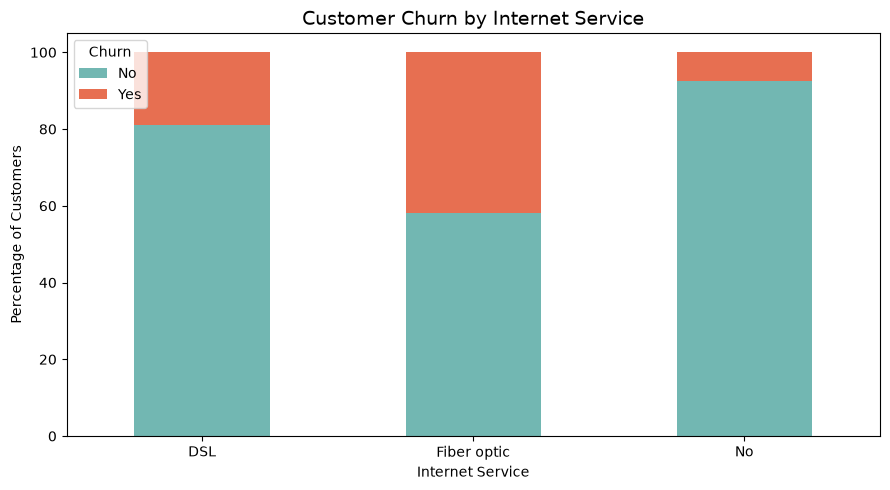

In [164]:
churn_by_internet.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Internet Service", fontsize=14)
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


**Observation:** Customers using Fiber optic internet service have the highest churn rate (41.89%), followed by DSL users (18.96%). Customers without internet service have the lowest churn rate (7.40%).

**Business Insight:** The company should investigate why Fiber optic customers leave more frequently. Possible areas to explore include service quality, pricing, and customer satisfaction before deciding on retention strategies.

In [165]:
churn_by_support = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_support

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


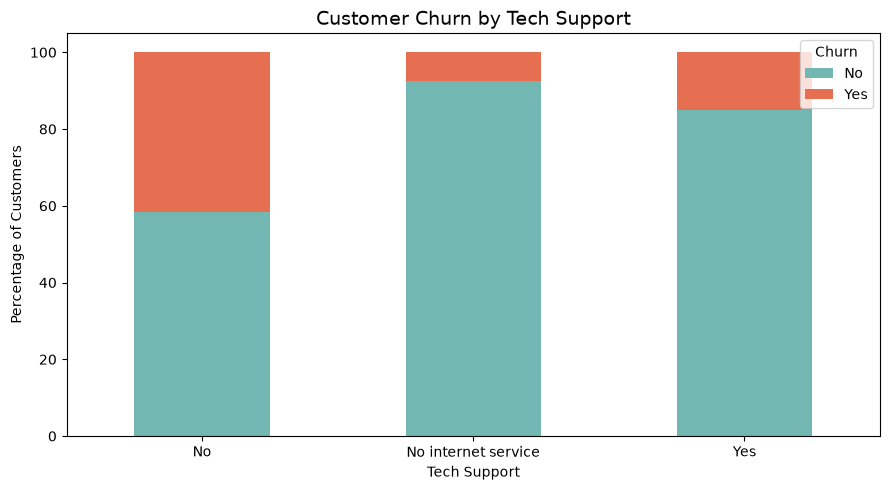

In [166]:
churn_by_support.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Tech Support", fontsize=14)
plt.xlabel("Tech Support")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers without technical support have the highest churn rate (41.64%). Customers with technical support have a lower churn rate (15.17%), while customers with no internet service have the lowest churn rate (7.40%).

**Business Insight:** The company could investigate whether better access to technical support helps improve customer retention. It should also explore why customers without technical support leave more frequently.

In [167]:
churn_by_security = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_security

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


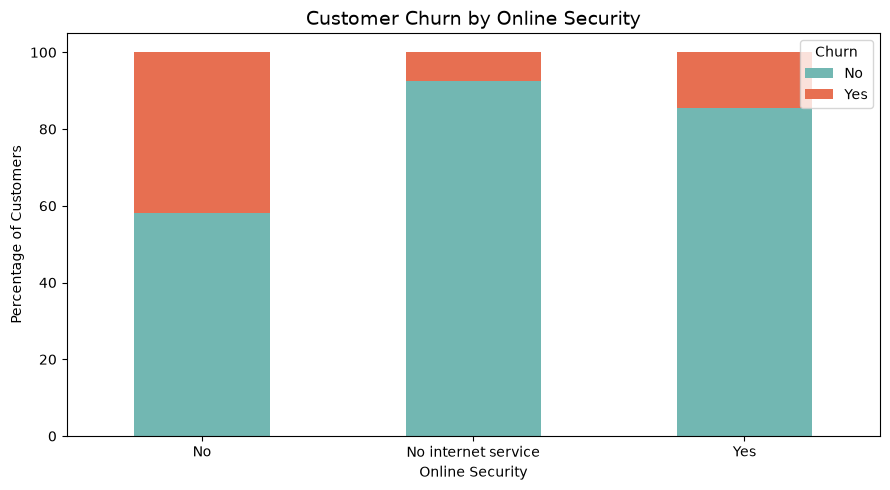

In [168]:
churn_by_security.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Online Security", fontsize=14)
plt.xlabel("Online Security")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers without online security have the highest churn rate (41.77%). Customers with online security have a lower churn rate (14.61%), while customers with no internet service have the lowest churn rate (7.40%).

**Business Insight:** The company could investigate whether online security services improve customer satisfaction and retention. It should explore why customers without online security leave more frequently before deciding on suitable retention strategies.

In [169]:
churn_by_billing = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_billing

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


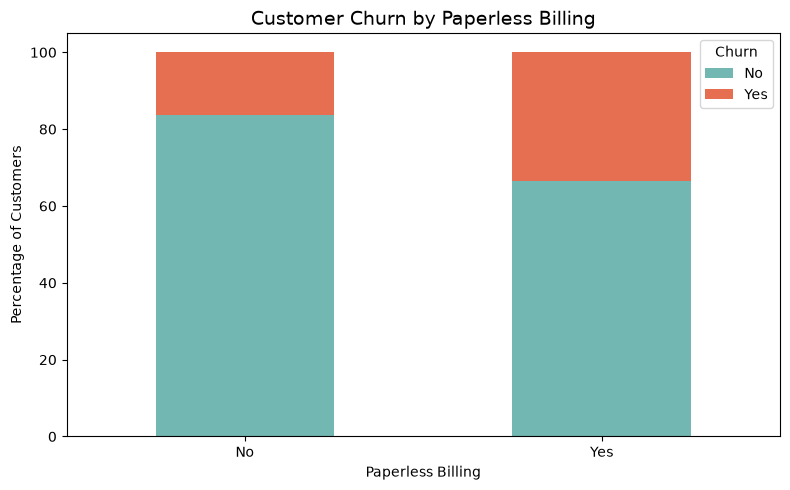

In [170]:
churn_by_billing.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Paperless Billing", fontsize=14)
plt.xlabel("Paperless Billing")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Customers who use paperless billing have a higher churn rate (33.57%) than customers who do not use paperless billing (16.33%).

**Business Insight:** The company could investigate whether paperless billing is associated with other factors that influence churn, such as payment methods, contract types, or customer preferences. It should avoid assuming that paperless billing itself causes customers to leave.

In [171]:
churn_by_senior = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_senior

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


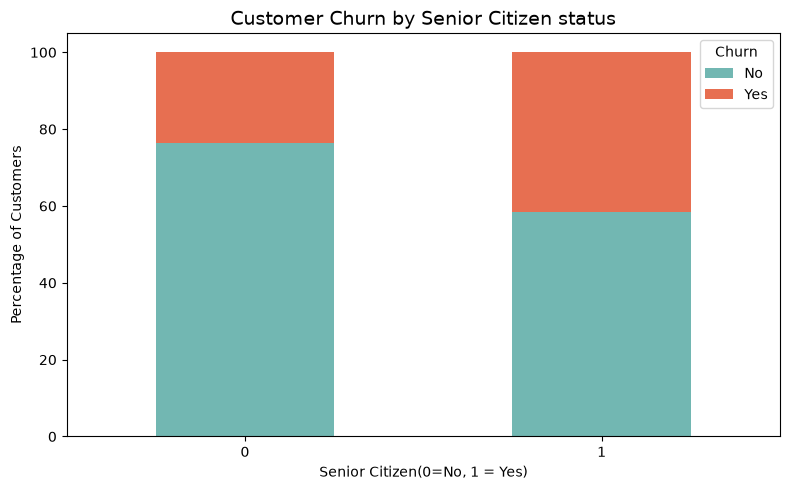

In [172]:
churn_by_senior.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=("#72B7B2", "#E76F51")
)

plt.title("Customer Churn by Senior Citizen status", fontsize=14)
plt.xlabel("Senior Citizen(0=No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**Observation:** Senior citizens have a higher churn rate (41.68%) than non-senior citizens (23.61%).

**Business Insight:** The company could investigate the needs and concerns of senior citizen customers and evaluate whether more suitable support or service plans could improve retention.

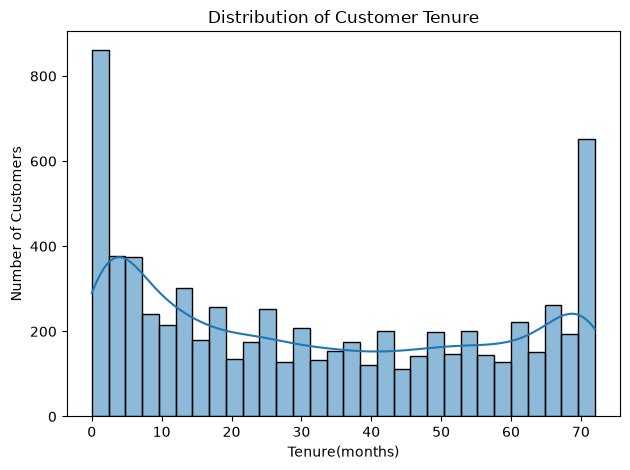

In [173]:
plt.Figure(figsize=(8,5))
sns.histplot(data=df,x="tenure",bins=30,kde = True)
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure(months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**Observation:** The histogram shows that the highest number of customers have a tenure of approximately 0–5 months. The second noticeable concentration appears among customers with a tenure above 70 months. This indicates that the dataset contains many very new customers as well as many long-term customers.

**Business Insight:** The company should focus on understanding the needs of new customers, as they may be more vulnerable to churn. It should also continue building loyalty among long-term customers to maintain retention.

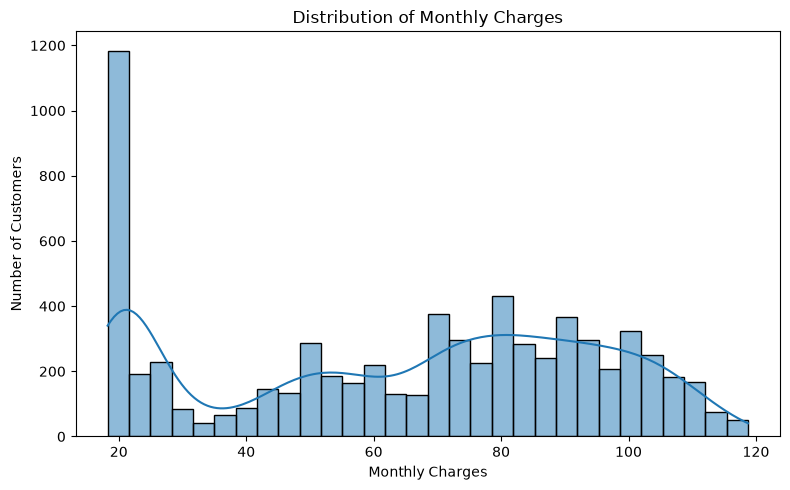

In [174]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyCharges", bins=30, kde=True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Observation
The histogram shows that the highest concentration of customers is around monthly charges of $20. This indicates that a large number of customers pay relatively low monthly charges.

### Business Insight
The company should understand the preferences and needs of customers with lower monthly charges and explore whether pricing, service plans, or additional services are associated with customer retention.

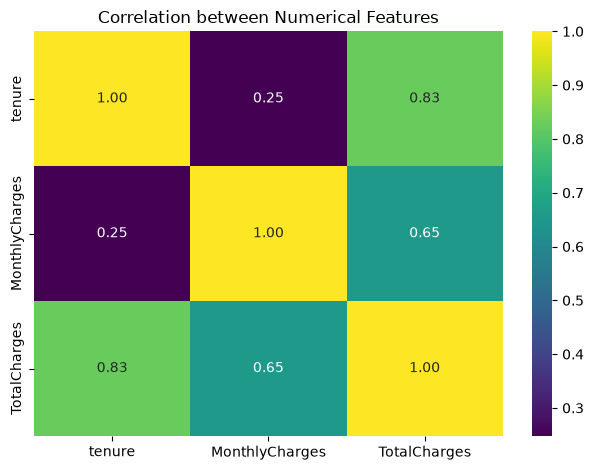

In [175]:
numerical_cols = ["tenure","MonthlyCharges","TotalCharges"]
correlation = df[numerical_cols].corr()
plt.Figure(figsize=(7,5))
sns.heatmap(correlation,annot=True,cmap="viridis",fmt =".2f")
plt.title("Correlation between Numerical Features")
plt.tight_layout()
plt.show()

In [176]:
correlation

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.247900,0.825880
MonthlyCharges,0.24790,1.000000,0.651065
TotalCharges,0.82588,0.651065,1.000000


### Observation
The heatmap shows a strong positive correlation (0.83) between tenure and TotalCharges. MonthlyCharges and TotalCharges also have a positive correlation (0.65), while tenure and MonthlyCharges have a weak positive correlation (0.25).

### Business Insight
TotalCharges is closely related to how long a customer stays and how much they pay monthly. The company can use these relationships to better understand customer billing patterns. However, correlation alone does not establish causation.

In [177]:
print(df["TotalCharges"].isnull().sum())
print(df["TotalCharges"].dtype)

11
float64


In [178]:
df.loc[df["TotalCharges"].isnull(), "TotalCharges"] = 0

print(df["TotalCharges"].isnull().sum())

0


In [179]:
df.select_dtypes(include="object").columns

C:\Users\krish\AppData\Local\Temp\ipykernel_21476\1196084386.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns


Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [180]:
for col in df.select_dtypes(include="object").columns:
    print(col,";",df[col].unique())

customerID ; <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
gender ; <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner ; <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents ; <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService ; <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines ; <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService ; <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity ; <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup ; <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection ; <StringArray>
['No', 'Yes', 'No internet 

C:\Users\krish\AppData\Local\Temp\ipykernel_21476\1993960821.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [181]:
df = df.drop("customerID",axis=1)

In [182]:
df.shape

(7043, 20)

In [183]:
binary_cols = ["gender","Partner","Dependents","PhoneService","PaperlessBilling"]
for col in binary_cols:
    print(col,df[col].unique())

gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PaperlessBilling <StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [184]:
df["gender"] = df["gender"].map({"Female":0,"Male":1})
binary_cols = ["Partner","Dependents","PhoneService","PaperlessBilling"]
for col in binary_cols:
    df[col]=df[col].map({"No":0,"Yes":1})

df[binary_cols +["gender"]].head()

,Partner,Dependents,PhoneService,PaperlessBilling,gender
0,1,0,0,1,0
1,0,0,1,0,1
2,0,0,1,1,1
3,0,0,0,0,1
4,0,0,1,1,0


In [185]:
df.select_dtypes(include = "str").columns

Index(['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaymentMethod', 'Churn'],
      dtype='str')

In [186]:
categorical_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaymentMethod']
df = pd.get_dummies(df,columns = categorical_cols,dtype=int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,No,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,No,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,Yes,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,No,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,Yes,...,1,0,0,1,0,0,0,0,1,0


In [187]:
df["Churn"] = df["Churn"].map(({"No":0,"Yes":1}))
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [188]:
print(df["Churn"].head(10))
print(df["Churn"].isnull().sum())
print(df["Churn"].dtype)

0    0
1    0
2    1
3    0
4    1
5    1
6    0
7    0
8    1
9    0
Name: Churn, dtype: int64
0
int64


In [189]:
original_churn = pd.read_csv(
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)["Churn"]

df["Churn"] = original_churn.map({
    "No": 0,
    "Yes": 1
})

print(df["Churn"].value_counts())
print("Missing values:", df["Churn"].isnull().sum())

Churn
0    5174
1    1869
Name: count, dtype: int64
Missing values: 0


In [190]:
X = df.drop("Churn",axis = 1)
y = df["Churn"]
print("Feature Shape: ",X.shape)
print("Target Shape: ",y.shape)

Feature Shape:  (7043, 40)
Target Shape:  (7043,)


In [191]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("X_train: ",X_train.shape)
print("X_test: ",X_test.shape)
print("y_train: ",y_train.shape)
print("y_test: ",y_test.shape)

X_train:  (5634, 40)
X_test:  (1409, 40)
y_train:  (5634,)
y_test:  (1409,)


### 5. Train-Test Split

The dataset was divided into training and testing sets using an 80:20 ratio.

- **Training set:** 5,634 rows
- **Testing set:** 1,409 rows
- **Number of features:** 40

The `train_test_split()` function was used with `random_state=42` to ensure reproducibility. The `stratify=y` parameter was used to maintain a similar proportion of churn and non-churn customers in both sets.

**Why is this step important?**

The training set is used to train the machine learning model, while the testing set is used to evaluate how well the model performs on unseen data.


### 6. Feature Scaling

Feature scaling is a preprocessing technique used to bring numerical features to a comparable scale.

In this project, `StandardScaler` is used to scale the following numerical features:

- `tenure`
- `MonthlyCharges`
- `TotalCharges`

The scaler is fitted only on the training data and then applied to both training and testing data. This prevents information from the test set from influencing the scaling process.

**Why is scaling needed?**

Features with different ranges can affect algorithms such as Logistic Regression. Standardization transforms features so that they have approximately zero mean and unit standard deviation in the training data.


In [192]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
scaler = StandardScaler()
num_cols = ["tenure","MonthlyCharges","TotalCharges"]
X_train[num_cols]=scaler.fit_transform(X_train[num_cols])
X_test[num_cols]=scaler.transform(X_test[num_cols])

X_train[num_cols].head()

,tenure,MonthlyCharges,TotalCharges
3738,0.102371,-0.521976,-0.262257
3151,-0.711743,0.337478,-0.503635
4860,-0.793155,-0.809013,-0.749883
3867,-0.263980,0.284384,-0.172722
3810,-1.281624,-0.676279,-0.989374


In [193]:
model = LogisticRegression(random_state=42)
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

### 8. Making Predictions

After training the Logistic Regression model, we use it to predict customer churn on the unseen testing dataset.

The `predict()` method generates a predicted class for each customer:
- `0`: Customer is predicted not to churn.
- `1`: Customer is predicted to churn.

These predictions will later be compared with the actual target values to evaluate model performance.


In [194]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[0 1 0 0 0 1 0 0 0 0]


In [195]:
print("Predicted values: ",y_pred[:10])
print("Actual values: ",y_test.iloc[:10].to_numpy())

Predicted values:  [0 1 0 0 0 1 0 0 0 0]
Actual values:  [0 0 0 0 0 0 0 0 0 1]


### 8.1 Comparing Predicted and Actual Values

The predicted churn labels were compared with the actual labels for the first ten test customers.

Seven out of ten predictions were correct, giving a sample accuracy of 70%.

However, this small sample is not sufficient to judge the overall model performance. The model will therefore be evaluated on the complete test set using classification metrics.


In [196]:
accuracy = accuracy_score(y_test,y_pred)
print("Test Accuracy(%): ",accuracy*100)

Test Accuracy(%):  80.55358410220013


### 9. Model Evaluation Using Accuracy

The Logistic Regression model achieved a test accuracy of approximately 80.55%.

Accuracy measures the proportion of all test predictions that were correct.

However, the dataset contains more non-churning customers than churning customers. Therefore, accuracy alone may not fully represent the model's ability to identify customers who are likely to churn.

Additional evaluation metrics, including precision, recall, F1-score, and the confusion matrix, will be used to assess model performance more comprehensively.


In [197]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### 9.1 Classification Report Analysis

The Logistic Regression model achieved an overall accuracy of 80.55%.

- **Non-churn customers (Class 0):** The model achieved 85% precision, 89% recall, and an F1-score of 87%.
- **Churning customers (Class 1):** The model achieved 66% precision, 56% recall, and an F1-score of 60%.

The model performs better at identifying non-churning customers than churning customers. It identifies approximately 56% of actual churners, meaning a substantial proportion of customers who leave may go undetected.

**Business insight:** Improving churn detection is an important next step. The model should be evaluated using the confusion matrix and may require further tuning to improve recall for the churn class.


In [198]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[926 109]
 [165 209]]


### 9.2 Confusion Matrix Analysis

The confusion matrix shows the following results on the test dataset:

- **True Negatives:** 926 non-churning customers were correctly identified.
- **False Positives:** 109 non-churning customers were incorrectly classified as churners.
- **False Negatives:** 165 actual churners were incorrectly classified as non-churners.
- **True Positives:** 209 actual churners were correctly identified.

The model correctly classified 1,135 out of 1,409 test customers, achieving approximately 80.55% accuracy.

**Business insight:** The model misses 165 actual churners. Reducing these false negatives could help a business identify more at-risk customers, although this may increase false positives. The appropriate balance depends on the cost of missed churners versus unnecessary retention offers.


### 10. Model Improvement

Although the baseline Logistic Regression model achieved 80.55% accuracy, its recall for the churn class was approximately 56%.

The next step is to explore whether adjusting the classification threshold can help identify more customers who are likely to churn. This may improve recall but can also increase false positives.


In [199]:
y_prob = model.predict_proba(X_test)
print(y_prob[:5])

[[0.95430402 0.04569598]
 [0.3157074  0.6842926 ]
 [0.94134955 0.05865045]
 [0.59829582 0.40170418]
 [0.97841236 0.02158764]]


In [200]:
y_pred_04 = (y_prob[:,1]>=0.4).astype(int)
print("Classification report(threshold=0.4): ")
print(classification_report(y_test,y_pred_04))
print("Confusion matrix: ")
print(confusion_matrix(y_test,y_pred_04))

Classification report(threshold=0.4): 
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion matrix: 
[[845 190]
 [124 250]]


### 10.1 Classification Threshold Comparison

The baseline Logistic Regression model used a classification threshold of 0.5. Reducing the threshold to 0.4 increased churn recall from approximately 56% to 67% and reduced false negatives from 165 to 124.

However, precision for the churn class decreased from 66% to 57%, while false positives increased from 109 to 190. Overall accuracy also decreased from 80.55% to approximately 77.86%.

**Business insight:** A lower threshold helps identify more customers at risk of churning, but it may also lead to unnecessary retention offers. The appropriate threshold depends on the business cost of missed churners versus false alarms.


### 11. Model Training Using Random Forest

Random Forest is a supervised machine learning algorithm that combines multiple decision trees to make predictions.

Unlike Logistic Regression, which models the relationship between features and the probability of churn, Random Forest can learn more complex, non-linear relationships.

In this project, we will train a Random Forest classifier and compare its performance with the baseline Logistic Regression model.


In [201]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=200,random_state=42,class_weight='balanced')
rf_model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [202]:
rf_pred = rf_model.predict(X_test)
print(rf_pred[:10])

[0 1 0 0 0 1 1 0 0 1]


In [203]:
rf_accuracy = accuracy_score(y_test,rf_pred)
print("Random Forest Accuracy(%): ",rf_accuracy*100)

Random Forest Accuracy(%):  76.86302342086586


In [204]:
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.86      0.81      0.84      1035
           1       0.56      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409



In [205]:
rf_cm = confusion_matrix(y_test,rf_pred)
print(rf_cm)

[[843 192]
 [134 240]]


### 11.1 Random Forest Evaluation

The Random Forest classifier achieved a test accuracy of approximately 76.86%. For the churn class, it achieved 56% precision, 64% recall, and an F1-score of 60%.

The confusion matrix shows that the model correctly identified 240 churners and missed 134 actual churners. It also incorrectly classified 192 non-churning customers as churners.

**Business insight:** Random Forest identified more actual churners than the baseline Logistic Regression model, but it also generated more false positives. This demonstrates the trade-off between identifying at-risk customers and incorrectly flagging customers who are not going to churn.


### 12. Model Training Using K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification. It predicts the class of a new data point by considering the classes of its nearest neighbors.

In this project, KNN will classify customers as churn (`1`) or non-churn (`0`). Since KNN relies on distances between data points, feature scaling is important.


In [206]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [207]:
knn_pred = knn_model.predict(X_test)
print(knn_pred[:10])

[0 1 0 1 0 1 0 0 0 1]


In [208]:
knn_accuracy = accuracy_score(y_test,knn_pred)
print("KNN Accuracy(%): ",knn_accuracy*100)

KNN Accuracy(%):  76.22427253371185


In [209]:
print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.83      0.85      0.84      1035
           1       0.55      0.53      0.54       374

    accuracy                           0.76      1409
   macro avg       0.69      0.69      0.69      1409
weighted avg       0.76      0.76      0.76      1409



### 12.1 KNN Model Evaluation

The K-Nearest Neighbors (KNN) classifier achieved a test accuracy of **76.22%**.

- **Non-churning customers (Class 0):** The model achieved 83% precision, 85% recall, and an F1-score of 84%.
- **Churning customers (Class 1):** The model achieved 55% precision, 53% recall, and an F1-score of 54%.

The model performs better at identifying non-churning customers than churning customers. It identifies approximately 53% of actual churners, while the remaining churners are incorrectly classified as non-churning customers.

**Business insight:** The current KNN model has limited ability to identify customers at risk of churning. Its performance may improve through hyperparameter tuning, such as experimenting with different values of `n_neighbors` and `weights`.


### 13. Model Training Using Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised machine learning algorithm that finds a decision boundary to separate different classes.

In this project, SVM will classify customers as churn (`1`) or non-churn (`0`). Feature scaling is important for SVM because it relies on distances and the scale of the features.

We will train an SVM classifier and evaluate its performance using the same test dataset.


In [210]:
from sklearn.svm import SVC
svm_model = SVC(kernel="rbf",class_weight="balanced",random_state=42)
svm_model.fit(X_train,y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [211]:
svm_pred=svm_model.predict(X_test)
print(svm_pred[:10])

[0 1 0 1 0 1 1 0 0 1]


In [212]:
svm_accuracy = accuracy_score(y_test,svm_pred)
print("SVM Accuracy(%): ",svm_accuracy*100)

SVM Accuracy(%):  74.59190915542938


In [213]:
print(classification_report(y_test,svm_pred))

              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



In [214]:
cm_svm = confusion_matrix(y_test,svm_pred)
print(cm_svm)

[[761 274]
 [ 84 290]]


### Overall Observation — SVM Model

The SVM model achieved an overall test accuracy of **74.59%**, with a precision of 51%, recall of 78%, and F1-score of 62% for the churn class.

The model correctly identified 290 out of 374 actual churners and missed 84 customers who actually churned. However, it incorrectly flagged 274 non-churning customers as potential churners.

Compared with Logistic Regression, SVM achieved higher churn recall (78% vs. 56%) and a slightly higher churn F1-score (62% vs. 60%), but lower accuracy (74.59% vs. 80.55%) and churn precision (51% vs. 66%).

**Business Insight:** SVM may be useful when identifying more at-risk customers is the priority. However, its high number of false positives could lead to unnecessary retention campaign costs. The final model should be selected based on the business objective and the cost of missed churners versus unnecessary retention offers.

## 14. Model Improvement and Hyperparameter Tuning

After training and evaluating four machine learning algorithms, we compared their performance using accuracy, precision, recall, F1-score, and the confusion matrix.

The baseline results showed that Logistic Regression achieved the highest accuracy of 80.55%, while SVM achieved the highest recall of 78% for the churn class.

However, no single model performed best across all evaluation metrics. Therefore, we will attempt to improve the existing models through hyperparameter tuning and further experiments.

### Objectives

- Improve Logistic Regression performance while maintaining good overall accuracy.
- Improve SVM performance, particularly the precision and F1-score for the churn class, while monitoring recall.
- Compare the tuned models with their baseline results.
- Select a final model based on evaluation metrics and the business objective of identifying customers at risk of churn.

**Note:** Model improvement is an experimental process. Tuning may not improve every metric, so all changes will be evaluated against the baseline results.

### 14.1 Hyperparameter Tuning — Logistic Regression

Hyperparameter tuning is the process of testing different model settings to find a configuration that performs well on unseen data.

In Logistic Regression, the parameter `C` controls the strength of regularization. Smaller values apply stronger regularization, while larger values apply weaker regularization.

We will use cross-validation to compare different values of `C` and identify a suitable configuration. We will focus on the F1-score for the churn class while also monitoring recall and accuracy.

In [217]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000),
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1-score:", grid_search.best_score_)

Best Parameters: {'C': 10}
Best Cross-Validation F1-score: 0.5974829820849967


In [218]:
best_lr = grid_search.best_estimator_
y_pred_lr_tuned = best_lr.predict(X_test)
print("Tuned Logistic Regression Accuracy(%): ",accuracy_score(y_test,y_pred_lr_tuned)*100)
print("\nClassification Report: ",classification_report(y_test,y_pred_lr_tuned))
print("\nConfusion Matrix: ",confusion_matrix(y_test,y_pred_lr_tuned))

Tuned Logistic Regression Accuracy(%):  80.62455642299503

Classification Report:                precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:  [[927 108]
 [165 209]]


### Logistic Regression Hyperparameter Tuning — Observation

Hyperparameter tuning was performed using GridSearchCV with five-fold stratified cross-validation. The best parameter was found to be `C = 10`, with a cross-validation F1-score of approximately 59.75% for the churn class.

On the test dataset, the tuned model achieved an accuracy of 80.62%, compared with 80.55% for the baseline model. However, churn precision, recall, and F1-score remained approximately unchanged.

**Conclusion:** Tuning the `C` parameter resulted in only a marginal improvement in accuracy and did not meaningfully improve churn detection. Further experiments may be needed to improve recall for the churn class.

### 14.2 Hyperparameter Tuning — SVM

The baseline SVM model achieved a churn recall of 78%, indicating that it identified a relatively high proportion of actual churners. However, its churn precision was 51%, and its overall accuracy was 74.59%.

We will tune the `C` and `gamma` parameters using stratified cross-validation to explore whether the model can achieve a better balance between precision and recall. The tuned model will then be evaluated on the test dataset and compared with the baseline SVM model.

In [219]:
param_grid_svm = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.01, 0.1]
}

cv_svm = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_svm = GridSearchCV(
    SVC(class_weight="balanced", kernel="rbf"),
    param_grid_svm,
    scoring="f1",
    cv=cv_svm,
    n_jobs=-1,
    verbose=1
)

grid_search_svm.fit(X_train, y_train)

print("Best Parameters:", grid_search_svm.best_params_)
print("Best Cross-Validation F1-score:", grid_search_svm.best_score_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


Best Parameters: {'C': 1, 'gamma': 'scale'}
Best Cross-Validation F1-score: 0.6256080889915476


In [220]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

best_svm = grid_search_svm.best_estimator_
y_pred_svm_tuned = best_svm.predict(X_test)

print("Tuned SVM Accuracy (%):",
      accuracy_score(y_test, y_pred_svm_tuned) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_tuned))

Tuned SVM Accuracy (%): 74.59190915542938

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409

Confusion Matrix:
[[761 274]
 [ 84 290]]


### Tuned SVM — Overall Observation

The SVM model was tuned using GridSearchCV with five-fold stratified cross-validation. The `C` and `gamma` hyperparameters were explored using F1-score as the evaluation metric.

The tuned SVM achieved a test accuracy of **74.59%**, with a precision of **51%**, recall of **78%**, and F1-score of **62%** for the churn class.

The confusion matrix shows that the model correctly identified 290 out of 374 actual churners, while missing 84 churners. However, it incorrectly classified 274 non-churning customers as potential churners.

**Comparison with the baseline:** The tuned model produced the same test metrics and confusion matrix as the original SVM. Therefore, hyperparameter tuning did not improve the model's observed test performance in this experiment.

**Conclusion:** The SVM model maintains relatively high churn recall, but its low precision and high number of false positives remain limitations. Further improvements should focus on finding a better balance between identifying actual churners and avoiding unnecessary retention campaigns.

**Hyperparameter Selection:** GridSearchCV selected `C = 1` and `gamma = 'scale'`, achieving a mean cross-validation F1-score of approximately 62.56%. These were the same settings used by the baseline SVM model.

This indicates that, among the tested hyperparameter combinations, the original configuration provided the best cross-validation F1-score. The tuned model consequently produced the same test-set predictions and evaluation metrics as the baseline model.

## 15. Final Model Comparison

In this section, we compare the performance of all four baseline machine learning models and the tuned Logistic Regression and SVM models.

The comparison uses accuracy, precision, recall, and F1-score for the churn class. These metrics help us understand overall predictive performance as well as how effectively each model identifies customers who are likely to churn.

The objective is to select a model that balances overall accuracy with effective churn detection.

In [221]:
print("Random Forest model exists:", "rf_model" in globals())
print("KNN model exists:", "knn_model" in globals())
print("SVM model exists:", "svm_model" in globals())
print("Tuned Logistic Regression exists:", "best_lr" in globals())
print("Tuned SVM exists:", "best_svm" in globals())

Random Forest model exists: True
KNN model exists: True
SVM model exists: True
Tuned Logistic Regression exists: True
Tuned SVM exists: True


In [222]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
models = {
    "Logistic Regression":(model,y_pred),
    "Tuned Logistic Regression":(best_lr,y_pred_lr_tuned),
    "Random Forest Classifier":(rf_model,rf_model.predict(X_test)),
    "K Neighbors Classifier":(knn_model,knn_model.predict(X_test)),
    "SVM":(svm_model,svm_pred),
    "Tuned Svm ":(best_svm,y_pred_svm_tuned)
}
results = []
for name,(trained_model,predictions) in models.items():
    results.append({
        "Model":name,
        "Accuracy (%)":round(accuracy_score(y_test,predictions)*100,2),
        "Churn Precision (%)": round(precision_score(y_test, predictions, pos_label=1) * 100, 2),
        "Churn Recall (%)": round(recall_score(y_test, predictions, pos_label=1) * 100, 2),
        "Churn F1-score (%)": round(f1_score(y_test, predictions, pos_label=1) * 100, 2)
    })
comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy (%),Churn Precision (%),Churn Recall (%),Churn F1-score (%)
0,Logistic Regression,80.55,65.72,55.88,60.40
1,Tuned Logistic Regression,80.62,65.93,55.88,60.49
2,Random Forest Classifier,76.86,55.56,64.17,59.55
3,K Neighbors Classifier,76.22,55.43,53.21,54.30
4,SVM,74.59,51.42,77.54,61.83
5,Tuned Svm,74.59,51.42,77.54,61.83


### Final Model Comparison — Observation

Six model configurations were evaluated using accuracy, churn precision, churn recall, and churn F1-score.

Tuned Logistic Regression achieved the highest accuracy of **80.62%** and the highest churn precision of **65.93%**. However, its churn recall was 55.88%, meaning that it failed to identify a considerable proportion of actual churners.

SVM and Tuned SVM achieved the highest churn recall of **77.54%** and the highest churn F1-score of **61.83%**. However, their churn precision was 51.42%, indicating a relatively high number of false-positive predictions.

Hyperparameter tuning produced only marginal improvements in Logistic Regression, while SVM's test-set performance remained unchanged.

**Conclusion:** Tuned Logistic Regression is a strong candidate when overall accuracy and precision are important. SVM is a suitable alternative when identifying a larger proportion of actual churners is the primary objective. The final model should be selected according to the business cost of missed churners versus unnecessary retention campaigns.

In [223]:
feature_imp = pd.DataFrame({
    "Feature":X_train.columns,
    "Importance":rf_model.feature_importances_
})
feature_imp = feature_imp.sort_values(by="Importance",ascending=False)
feature_imp.head(15)

,Feature,Importance
8,TotalCharges,0.149267
4,tenure,0.134802
7,MonthlyCharges,0.133381
33,Contract_Month-to-month,0.080023
35,Contract_Two year,0.036245
24,TechSupport_No,0.036176
15,OnlineSecurity_No,0.030619
13,InternetService_Fiber optic,0.027872
38,PaymentMethod_Electronic check,0.027251
0,gender,0.024774


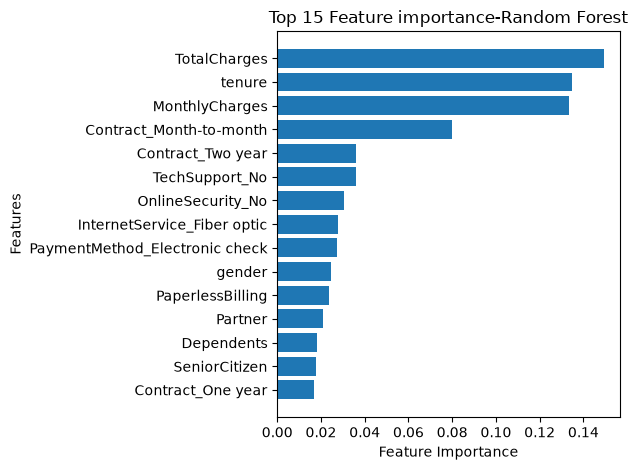

In [224]:
top_features = feature_imp.head(15).sort_values(by="Importance",ascending=True)
plt.Figure(figsize=(10,7))
plt.barh(top_features["Feature"],top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Feature importance-Random Forest")
plt.tight_layout()
plt.show()

### Feature Importance — Observation

The Random Forest feature importance analysis identified `TotalCharges` (14.93%), `tenure` (13.48%), and `MonthlyCharges` (13.34%) as the three most important features.

Contract type was also important, particularly the month-to-month contract feature (8.00%). Other useful features included the absence of Tech Support, the absence of Online Security, Fiber Optic internet service, and Electronic Check payment.

These results suggest that customer tenure, billing-related attributes, and contract characteristics are important for the Random Forest model's churn predictions. However, feature importance indicates predictive usefulness rather than causation, and it does not show whether a feature increases or decreases churn risk.

### 16.1 Permutation Importance

Permutation importance evaluates the importance of a feature by randomly shuffling its values and measuring the resulting change in model performance on unseen data.

If shuffling a feature reduces the model's performance substantially, that feature may contain useful predictive information. We will use the F1-score to evaluate the impact on churn prediction.

In [225]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

permutation_df.head(15)

,Feature,Importance
33,Contract_Month-to-month,0.062889
4,tenure,0.044201
8,TotalCharges,0.025099
13,InternetService_Fiber optic,0.018342
35,Contract_Two year,0.007013
2,Partner,0.006675
1,SeniorCitizen,0.005803
34,Contract_One year,0.005636
7,MonthlyCharges,0.004942
39,PaymentMethod_Mailed check,0.002883


### Permutation Importance — Observation

Permutation importance was calculated using the Random Forest model on the test dataset, with the churn F1-score as the evaluation metric.

`Contract_Month-to-month` had the highest permutation importance (0.0629), followed by `tenure` (0.0442), `TotalCharges` (0.0251), and `InternetService_Fiber optic` (0.0183).

Unlike the Random Forest's built-in importance, which ranked `TotalCharges` first, permutation importance ranked `Contract_Month-to-month` first. This difference occurs because the two methods measure feature importance differently.

Overall, the results highlight contract type and customer tenure as particularly useful features for churn prediction on the test dataset. These findings indicate predictive usefulness, not causation.

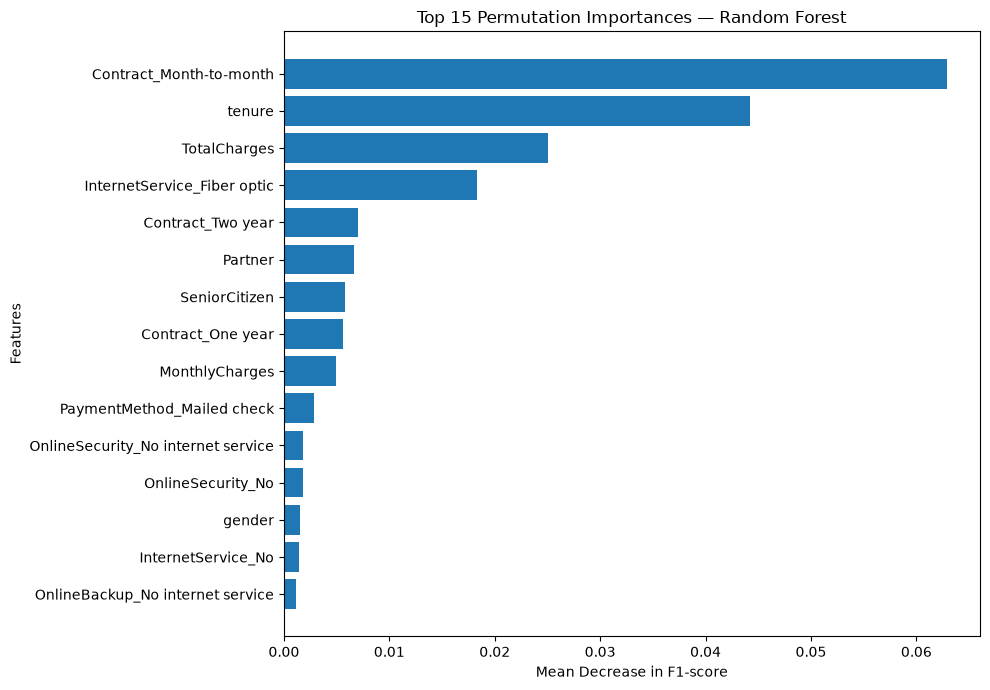

In [226]:
import matplotlib.pyplot as plt

top_perm = permutation_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_perm["Feature"], top_perm["Importance"])

plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Features")
plt.title("Top 15 Permutation Importances — Random Forest")
plt.tight_layout()
plt.show()

## 17. Comparison of Feature Importance Methods

The Random Forest model was analyzed using two feature importance techniques: built-in feature importance and permutation importance.

Built-in feature importance ranked `TotalCharges`, `tenure`, and `MonthlyCharges` as the top three features. In contrast, permutation importance ranked `Contract_Month-to-month` first, followed by `tenure` and `TotalCharges`.

The difference occurs because built-in importance measures how features contribute to tree splits, whereas permutation importance measures how much predictive performance decreases when a feature's values are shuffled.

Considering both methods, contract type, customer tenure, and billing-related attributes appear to be useful for predicting customer churn. These findings describe predictive patterns and should not be interpreted as proof of causation.

## 18. Final Conclusion

In this project, customer churn prediction was performed using the Telco Customer Churn dataset. The workflow included data cleaning, exploratory data analysis, preprocessing, model training, evaluation, hyperparameter tuning, and feature importance analysis.

Four baseline machine learning algorithms were evaluated: Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM). Hyperparameter tuning was also performed for Logistic Regression and SVM.

Tuned Logistic Regression achieved the highest test accuracy of **80.62%**, with churn precision of **65.93%** and churn recall of **55.88%**. SVM achieved the highest churn recall of **77.54%** and the highest churn F1-score of **61.83%** among the evaluated configurations.

Feature importance analysis highlighted customer tenure, billing-related attributes, and contract type as useful predictors. Permutation importance particularly highlighted the month-to-month contract feature.

Overall, the project demonstrates how machine learning can help identify customers who may be at risk of churn. The most suitable model depends on the business objective, especially the trade-off between missing actual churners and incorrectly flagging customers who would stay.

**Future Scope:** The project can be extended by developing an interactive Streamlit application, improving churn detection through additional experiments, and evaluating model performance and business costs on new customer data.

In [227]:
print("Scaler available:", "scaler" in globals())
print("Best Logistic Regression available:", "best_lr" in globals())
print("Training columns available:", "X_train" in globals())
print("Original dataset available:", "df" in globals())

Scaler available: True
Best Logistic Regression available: True
Training columns available: True
Original dataset available: True


In [228]:
final_model = grid_search_svm.best_estimator_

print("Final Model:", final_model)
print("Best Parameters:", grid_search_svm.best_params_)

Final Model: SVC(C=1, class_weight='balanced')
Best Parameters: {'C': 1, 'gamma': 'scale'}


### Why Tuned SVM Was Selected as the Final Model

After comparing Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM), Tuned SVM was selected as the final model based on its performance in identifying customers likely to churn.

- **Highest Churn Recall (77.54%):** Tuned SVM correctly identified a larger proportion of actual churners than the other evaluated models. This is important because missing potential churners can lead to customer and revenue loss.
- **Highest Churn F1-score (61.83%):** It achieved the best balance between precision and recall for the churn class among the evaluated models.
- **Hyperparameter Tuning:** GridSearchCV was used to evaluate different combinations of `C` and `gamma` using 5-fold stratified cross-validation. The best parameters were `C = 1` and `gamma = 'scale'`.
- **Class Imbalance Handling:** The model used `class_weight="balanced"` to give appropriate importance to both churn and non-churn classes.
- **Business Relevance:** Its higher recall makes it useful for identifying more customers who may leave the telecom service, allowing the company to consider targeted retention strategies.

Although Tuned Logistic Regression achieved higher accuracy (80.62%), Tuned SVM achieved a higher churn recall (77.54%) and F1-score (61.83%). Since identifying potential churners is a key objective of this project, Tuned SVM was selected as the final model.

**Conclusion:** Tuned SVM is the final model for this project because of its stronger churn detection performance. Its predictions and business impact should be further evaluated before real-world deployment.

## 19. Model Deployment Using Streamlit

After completing data preprocessing, exploratory data analysis, model training, evaluation, hyperparameter tuning, and feature importance analysis, the Tuned Support Vector Machine (SVM) was selected as the final model.

To make the model accessible and interactive, the next phase of the project focuses on developing a web application using **Streamlit**.

The application will allow users to enter customer details and receive a prediction indicating whether the customer is likely to churn or stay.

### Objectives
- Load the saved Tuned SVM model.
- Apply the same preprocessing and feature transformations used during training.
- Create an interactive interface for entering customer information.
- Display the predicted customer churn outcome.

This deployment phase will demonstrate how a trained machine learning model can be integrated into a user-friendly application.

In [232]:
import joblib
joblib.dump(final_model,"final_svm_model.pkl")
joblib.dump(scaler,"scaler.pkl")
joblib.dump(X_train.columns.tolist(), "feature_columns.pkl")
print("Model & Scaler saved successfully")

Model & Scaler saved successfully


In [230]:
import os

print("Model file exists:", os.path.exists("final_svm_model.pkl"))
print("Scaler file exists:", os.path.exists("scaler.pkl"))

Model file exists: True
Scaler file exists: True


In [231]:
print("Number of Features: ",len(X_train.columns))
print("\nFeature names:")
print(X_train.columns.tolist())

Number of Features:  40

Feature names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mai

In [233]:
import os
print(os.getcwd())

c:\Users\krish\OneDrive\Documents\Projects\Cutomer_Churn_Prediction


In [234]:
import os

print("Model:", os.path.exists("final_svm_model.pkl"))
print("Scaler:", os.path.exists("scaler.pkl"))
print("Feature columns:", os.path.exists("feature_columns.pkl"))

Model: True
Scaler: True
Feature columns: True


In [235]:
import joblib

model = joblib.load("final_svm_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")
loaded_columns = joblib.load("feature_columns.pkl")

print("Model loaded:", type(model))
print("Scaler loaded:", type(loaded_scaler))
print("Number of features:", len(loaded_columns))

Model loaded: <class 'sklearn.svm._classes.SVC'>
Scaler loaded: <class 'sklearn.preprocessing._data.StandardScaler'>
Number of features: 40


In [236]:
import sys
print(sys.executable)

c:\Users\krish\AppData\Local\Programs\Python\Python313\python.exe
